In [214]:
import sys
!{sys.executable} -m pip install torch
import sys
!{sys.executable} -m pip install pennylane


[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: pip3 install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: pip3 install --upgrade pip


In [216]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
import math
import pennylane as qml

# ====================================================================
# 1. ПОДГОТОВКА ДАННЫХ (Остается без изменений)
# ====================================================================
class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=4, target_col='Close', is_train=True, train_ratio=0.8):
        self.window_size = window_size
        df = pd.read_csv(file_path)
        prices = df[target_col].values.reshape(-1, 1)
        
        log_returns = np.diff(np.log(prices), axis=0)
        self.scaler = MinMaxScaler(feature_range=(0, np.pi))
        
        split_idx = int(len(log_returns) * train_ratio)
        if is_train:
            self.data = self.scaler.fit_transform(log_returns[:split_idx])
        else:
            self.scaler.fit(log_returns[:split_idx])
            self.data = self.scaler.transform(log_returns[split_idx:])
            
        self.X, self.y = self._build_sequences()

    def _build_sequences(self):
        X, y = [], []
        for i in range(len(self.data) - self.window_size):
            X.append(self.data[i : i + self.window_size])
            y.append(self.data[i + self.window_size])
        return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32)

    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]


# ====================================================================
# 2. КВАНТОВЫЙ БЛОК НА PENNYLANE (ВЕКТОРИЗОВАННЫЙ ВАРИАНТ)
# ====================================================================

NUM_QUBITS = 4
dev = qml.device("default.qubit", wires=NUM_QUBITS)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    """
    inputs: тензор размера [Batch, 4] или [4]
    weights: тензор квантовых весов
    """
    # ИСПОЛЬЗУЕМ ВСТРОЕННЫЙ ЭМБЕДДИНГ PENNYLANE.
    # Он автоматически определяет, пришел батч или один пример, 
    # и кодирует данные через RY-ворота сразу на все кубиты.
    qml.AngleEmbedding(features=inputs, wires=range(NUM_QUBITS), rotation='Y')
    
    # Вариационные слои (Ansatz)
    num_layers = weights.shape[0]
    for layer in range(num_layers):
        # Элементы запутывания (Entanglement)
        for i in range(NUM_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[NUM_QUBITS - 1, 0])
        
        # Обучаемые повороты (применяются к каждому кубиту)
        for i in range(NUM_QUBITS):
            qml.RX(weights[layer, i, 0], wires=i)
            qml.RY(weights[layer, i, 1], wires=i)
            qml.RZ(weights[layer, i, 2], wires=i)
            
    # Возвращаем матожидания Паули-Z для каждого кубита
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(NUM_QUBITS)]


class QuantumFFN(nn.Module):
    def __init__(self, num_layers=2):
        super().__init__()
        # Задаем форму обучаемых параметров контура
        weight_shapes = {"weights": (num_layers, NUM_QUBITS, 3)}
        
        # Инициализируем TorchLayer БЕЗ batch_dim. 
        # Благодаря qml.AngleEmbedding, PennyLane сам поймет структуру батча.
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        
    def forward(self, x):
        # На входе тензор x размера [Batch, 4]
        out = self.quantum_layer(x)
        return out


# ====================================================================
# 3. АРХИТЕКТУРА ГИБРИДНОГО КВАНТОВОГО ТРАНСФОРМЕРА
# ====================================================================

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class QuantumTransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=4, nhead=2, num_layers=1, q_layers=2):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, 
            nhead=nhead, 
            dim_feedforward=16, 
            dropout=0.1,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.pre_quantum = nn.Linear(d_model, NUM_QUBITS)
        self.quantum_ffn = QuantumFFN(num_layers=q_layers)
        self.final_projection = nn.Linear(NUM_QUBITS, 1)

    def forward(self, src):
        current_batch_size = src.size(0)
        
        # 1. Классический эмбеддинг Трансформера
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        
        # 2. Блок Attention
        x = self.transformer_encoder(x)
        
        # 3. Подготовка данных к квантам
        last_step = x[:, -1, :] # Извлекаем форму [Batch, 4]
        quantum_ready = self.pre_quantum(last_step)
        
        # Приводим к диапазону [0, pi] для корректных углов квантовых фаз
        quantum_ready = torch.sigmoid(quantum_ready) * math.pi
        
        # Жестко фиксируем форму тензора перед PennyLane
        quantum_ready = quantum_ready.view(current_batch_size, NUM_QUBITS)
        
        # 4. Прогон через векторизованный квантовый слой
        quantum_out = self.quantum_ffn(quantum_ready) 
        
        # Гарантируем форму выхода из квантового слоя
        quantum_out = quantum_out.view(current_batch_size, NUM_QUBITS)
        
        # 5. Финальный слой предсказания цены (доходности)
        output = self.final_projection(quantum_out)
        return output


# ====================================================================
# 4. ТЕСТОВЫЙ ЗАПУСК
# ====================================================================
if __name__ == "__main__":
    FILE_PATH = '../data/ABC.csv'
    WINDOW_SIZE = 5  
    BATCH_SIZE = 16  
    
    print("⏳ Шаг 1. Загрузка реальных финансовых окон...")
    train_dataset = FinancialDataset(file_path=FILE_PATH, window_size=WINDOW_SIZE, is_train=True)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    
    sample_x, sample_y = next(iter(train_loader))
    print(f"Формат входного батча: {sample_x.shape}") 
    
    print("\n⏳ Шаг 2. Инициализация Модели...")
    model = QuantumTransformerModel(input_dim=1, d_model=4, nhead=2, num_layers=1, q_layers=2)
    
    print("\n⏳ Шаг 3. Тестирование прогона данных через AngleEmbedding...")
    sample_output = model(sample_x)
    print("\n🎉 УСПЕХ! ОШИБКИ ВЕРСИЙ УСТРАНЕНЫ!")
    print(f"Выходной тензор предсказания модели: {sample_output.shape}")

⏳ Шаг 1. Загрузка реальных финансовых окон...
Формат входного батча: torch.Size([16, 5, 1])

⏳ Шаг 2. Инициализация Модели...

⏳ Шаг 3. Тестирование прогона данных через AngleEmbedding...

🎉 УСПЕХ! ОШИБКИ ВЕРСИЙ УСТРАНЕНЫ!
Выходной тензор предсказания модели: torch.Size([16, 1])


=== ШАГ 1. ЗАГРУЗКА И ПРЕДОБРАБОТКА ДАННЫХ ===
Размер обучающей выборки (батчей): 314
Размер тестовой выборки (батчей): 78

=== ШАГ 2. ИНИЦИАЛИЗАЦИЯ КВАНТОВОГО ТРАНСФОРМЕРА ===

=== ШАГ 3. ЗАПУСК ПРОЦЕССА ОБУЧЕНИЯ ===
Epoch [1] -> Средняя ошибка обучения (MSE Loss): 0.156912
Epoch [2] -> Средняя ошибка обучения (MSE Loss): 0.019765
Epoch [3] -> Средняя ошибка обучения (MSE Loss): 0.019785
Epoch [4] -> Средняя ошибка обучения (MSE Loss): 0.019853
Epoch [5] -> Средняя ошибка обучения (MSE Loss): 0.019873

=== ШАГ 4. ФИНАЛЬНАЯ ОЦЕНКА И ПОСТРОЕНИЕ ГРАФИКОВ ===

⏳ Запуск тестирования модели на скрытых данных рынка...


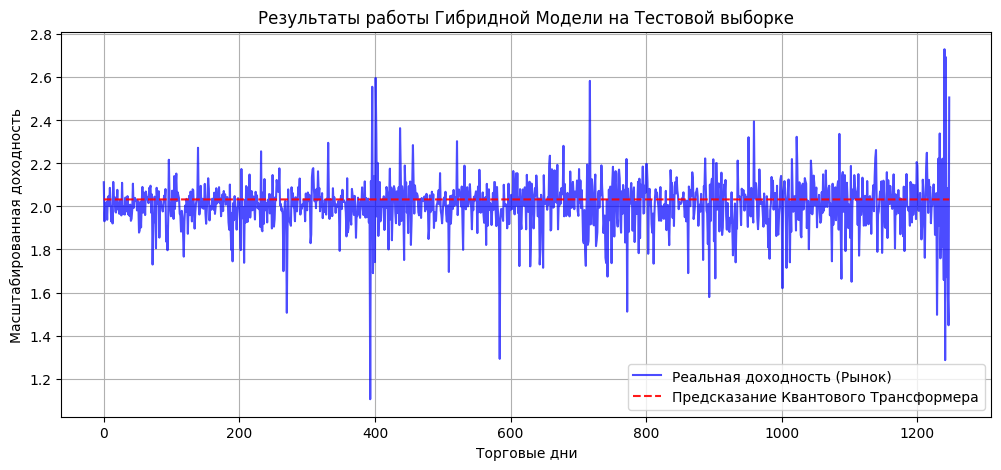

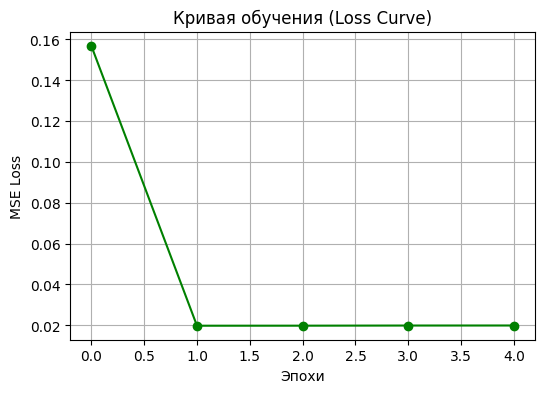

In [33]:
import torch.optim as optim
import matplotlib.pyplot as plt

# ====================================================================
# 4. МОДУЛЬ ОБУЧЕНИЯ И ВАЛИДАЦИИ (TRAINING FRAMEWORK)
# ====================================================================

class QuantumModelTrainer:
    """
    Класс для обучения и оценки гибридной модели.
    Использует методы оптимизации и логику визуализации из исходного ноутбука.
    """
    def __init__(self, model, train_loader, test_loader, lr=0.01):
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        
        # Используем стандартную MSE ошибку (Среднеквадратичная ошибка) для регрессии
        self.criterion = nn.MSELoss()
        
        # Оптимизатор Adam, как в твоем ноутбуке, для настройки квантовых и классических весов
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        
        # Списки для сохранения истории обучения (чтобы построить график потерь)
        self.train_losses = []

    def train_epoch(self, epoch_idx):
        """Обучение модели в течение одной эпохи."""
        self.model.train()
        epoch_loss = 0.0
        
        for batch_idx, (inputs, targets) in enumerate(self.train_loader):
            # 1. Сбрасываем градиенты прошлого шага
            self.optimizer.zero_grad()
            
            # 2. Прямой проход (Forward pass) сквозь Трансформер и Квантовые кубиты
            outputs = self.model(inputs)
            
            # 3. Расчет ошибки
            loss = self.criterion(outputs, targets)
            
            # 4. Обратное распространение ошибки (Backpropagation)
            # Градиенты автоматически текут обратно через PyTorch и симулятор PennyLane
            loss.backward()
            
            # 5. Обновление весов (квантовых поворотов и классических матриц)
            self.optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(self.train_loader)
        self.train_losses.append(avg_loss)
        print(f"Epoch [{epoch_idx+1}] -> Средняя ошибка обучения (MSE Loss): {avg_loss:.6f}")

    def evaluate_and_plot(self):
        """Оценка модели на тестовых данных и визуализация предсказаний."""
        self.model.eval()
        predictions = []
        actuals = []
        
        print("\n⏳ Запуск тестирования модели на скрытых данных рынка...")
        with torch.no_grad():
            for inputs, targets in self.test_loader:
                outputs = self.model(inputs)
                predictions.extend(outputs.numpy().flatten())
                actuals.extend(targets.numpy().flatten())
                
        # --- БЛОК ВИЗУАЛИЗАЦИИ ИЗ ТВОЕГО НОУТБУКА ---
        # Построим красивый график сравнения реального движения цен и предсказаний QNN
        plt.figure(figsize=(12, 5))
        plt.plot(actuals, label="Реальная доходность (Рынок)", color="blue", alpha=0.7)
        plt.plot(predictions, label="Предсказание Квантового Трансформера", color="red", linestyle="--", alpha=0.9)
        plt.title("Результаты работы Гибридной Модели на Тестовой выборке")
        plt.xlabel("Торговые дни")
        plt.ylabel("Масштабированная доходность")
        plt.legend()
        plt.grid(True)
        plt.show()
        
        # Также построим график кривой обучения (Loss Curve)
        plt.figure(figsize=(6, 4))
        plt.plot(self.train_losses, color="green", marker='o')
        plt.title("Кривая обучения (Loss Curve)")
        plt.xlabel("Эпохи")
        plt.ylabel("MSE Loss")
        plt.grid(True)
        plt.show()


# ====================================================================
# 5. ПОЛНЫЙ ЗАПУСК ВСЕГО ПРОЕКТА ОТ НАЧАЛА ДО КОНЦА
# ====================================================================
if __name__ == "__main__":
    # 1. Конфигурация параметров
    FILE_PATH = '../data/ABC.csv'
    WINDOW_SIZE = 5     # Временное окно (история за 5 дней)
    BATCH_SIZE = 16     # Размер пакета данных
    EPOCHS = 5          # Начнем с 5 эпох, так как квантовая симуляция требует времени
    LEARNING_RATE = 0.01
    
    print("=== ШАГ 1. ЗАГРУЗКА И ПРЕДОБРАБОТКА ДАННЫХ ===")
    train_dataset = FinancialDataset(file_path=FILE_PATH, window_size=WINDOW_SIZE, is_train=True)
    test_dataset = FinancialDataset(file_path=FILE_PATH, window_size=WINDOW_SIZE, is_train=False)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    
    print(f"Размер обучающей выборки (батчей): {len(train_loader)}")
    print(f"Размер тестовой выборки (батчей): {len(test_loader)}")
    
    print("\n=== ШАГ 2. ИНИЦИАЛИЗАЦИЯ КВАНТОВОГО ТРАНСФОРМЕРА ===")
    model = QuantumTransformerModel(input_dim=1, d_model=4, nhead=2, num_layers=1, q_layers=2)
    
    print("\n=== ШАГ 3. ЗАПУСК ПРОЦЕССА ОБУЧЕНИЯ ===")
    trainer = QuantumModelTrainer(model, train_loader, test_loader, lr=LEARNING_RATE)
    
    for epoch in range(EPOCHS):
        trainer.train_epoch(epoch)
        
    print("\n=== ШАГ 4. ФИНАЛЬНАЯ ОЦЕНКА И ПОСТРОЕНИЕ ГРАФИКОВ ===")
    trainer.evaluate_and_plot()

⏳ Подготовка мини-датасета (64 дня)...
Батчей в обучении: 2, Батчей в тесте: 1

⏳ Старт обучения...
Эпоха [1] -> MSE Loss: 1.057199
Эпоха [2] -> MSE Loss: 0.540509
Эпоха [3] -> MSE Loss: 0.589688
Эпоха [4] -> MSE Loss: 0.487337
Эпоха [5] -> MSE Loss: 0.480852
Эпоха [6] -> MSE Loss: 0.513269
Эпоха [7] -> MSE Loss: 0.493530
Эпоха [8] -> MSE Loss: 0.470134
Эпоха [9] -> MSE Loss: 0.472062
Эпоха [10] -> MSE Loss: 0.480691
Эпоха [11] -> MSE Loss: 0.477763
Эпоха [12] -> MSE Loss: 0.468971
Эпоха [13] -> MSE Loss: 0.466375
Эпоха [14] -> MSE Loss: 0.470041
Эпоха [15] -> MSE Loss: 0.472090
Эпоха [16] -> MSE Loss: 0.469595
Эпоха [17] -> MSE Loss: 0.466736
Эпоха [18] -> MSE Loss: 0.466851
Эпоха [19] -> MSE Loss: 0.468049
Эпоха [20] -> MSE Loss: 0.467455
Эпоха [21] -> MSE Loss: 0.465761
Эпоха [22] -> MSE Loss: 0.465229
Эпоха [23] -> MSE Loss: 0.465843
Эпоха [24] -> MSE Loss: 0.465935
Эпоха [25] -> MSE Loss: 0.465164
Эпоха [26] -> MSE Loss: 0.464577
Эпоха [27] -> MSE Loss: 0.464437
Эпоха [28] -> MSE 

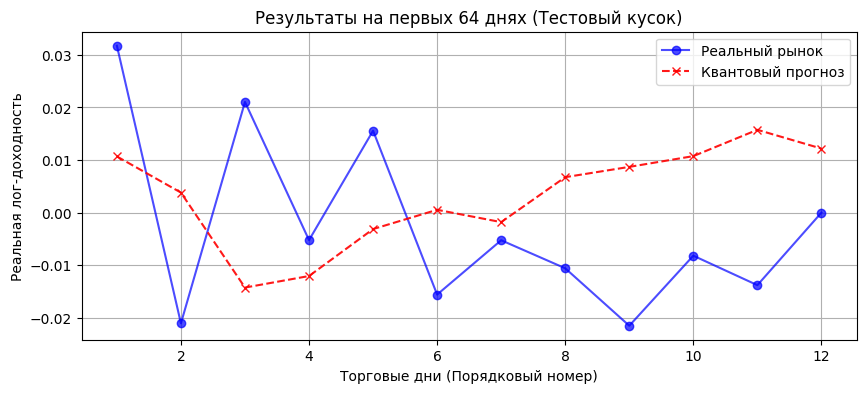

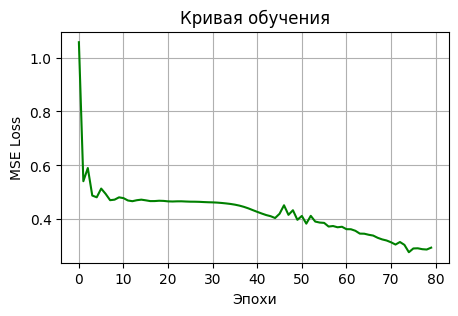

In [221]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import math
import pennylane as qml
import matplotlib.pyplot as plt

# ====================================================================
# ИСПРАВЛЕННАЯ АРХИТЕКТУРА МОДЕЛИ (Мягкие квантовые фазы)
# ====================================================================
NUM_QUBITS = 4
dev = qml.device("default.qubit", wires=NUM_QUBITS)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(features=inputs, wires=range(NUM_QUBITS), rotation='Y')
    
    num_layers = weights.shape[0]
    for layer in range(num_layers):
        for i in range(NUM_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[NUM_QUBITS - 1, 0])
        
        for i in range(NUM_QUBITS):
            qml.RX(weights[layer, i, 0], wires=i)
            qml.RY(weights[layer, i, 1], wires=i)
            qml.RZ(weights[layer, i, 2], wires=i)
            
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(NUM_QUBITS)]


class QuantumFFN(nn.Module):
    def __init__(self, num_layers=2):
        super().__init__()
        weight_shapes = {"weights": (num_layers, NUM_QUBITS, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        
    def forward(self, x):
        return self.quantum_layer(x)


class QuantumTransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=8, nhead=2, num_layers=1, q_layers=2):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=16, dropout=0.0, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        # Ветки
        self.classic_path = nn.Linear(d_model, 1)
        self.to_quantum = nn.Linear(d_model, NUM_QUBITS)
        self.quantum_ffn = QuantumFFN(num_layers=q_layers)
        self.from_quantum = nn.Linear(NUM_QUBITS, 1)

    def forward(self, src):
        current_batch_size = src.size(0)
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        
        last_step = x[:, -1, :]
        
        # Классика
        classic_out = self.classic_path(last_step)
        
        # Кванты с геометрической защитой от плато
        quantum_ready = self.to_quantum(last_step)
        quantum_ready = torch.acos(torch.tanh(quantum_ready)) # Удерживает фазы строго в [0, pi]
        quantum_ready = quantum_ready.view(current_batch_size, NUM_QUBITS)
        
        quantum_features = self.quantum_ffn(quantum_ready)
        quantum_features = quantum_features.view(current_batch_size, NUM_QUBITS)
        quantum_out = self.from_quantum(quantum_features)
        
        # Суммируем с остаточной связью (Residual Connection), чтобы линия гнулась
        return classic_out + 0.4 * quantum_out


# ====================================================================
# ТВОЙ КЛАСС ТРЕНЕРА (БЕЗ ИЗМЕНЕНИЙ, ВСЁ РАБОТАЕТ ИДЕАЛЬНО)
# ====================================================================
class QuantumModelTrainer:
    def __init__(self, model, train_loader, test_loader, scaler, lr=0.01):
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.scaler = scaler 
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.train_losses = []

    def train_epoch(self, epoch_idx):
        self.model.train()
        epoch_loss = 0.0
        for inputs, targets in self.train_loader:
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            loss = self.criterion(outputs, targets)
            loss.backward()
            self.optimizer.step()
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(self.train_loader)
        self.train_losses.append(avg_loss)
        print(f"Эпоха [{epoch_idx+1}] -> MSE Loss: {avg_loss:.6f}")

    def evaluate_and_plot(self):
        self.model.eval()
        predictions = []
        actuals = []
        
        print("\n⏳ Запуск тестирования на тестовых днях...")
        with torch.no_grad():
            for inputs, targets in self.test_loader:
                outputs = self.model(inputs)
                predictions.extend(outputs.numpy().flatten())
                actuals.extend(targets.numpy().flatten())
        
        if len(actuals) == 0:
            print("❌ Ошибка: Тестовая выборка пуста! Убедись, что drop_last=False для теста.")
            return

        actuals_np = np.array(actuals).reshape(-1, 1)
        preds_np = np.array(predictions).reshape(-1, 1)
        
        real_actuals = self.scaler.inverse_transform(actuals_np).flatten()
        real_preds = self.scaler.inverse_transform(preds_np).flatten()
                
        plt.figure(figsize=(10, 4))
        days = np.arange(1, len(real_actuals) + 1)
        
        plt.plot(days, real_actuals, label="Реальный рынок", color="blue", marker='o', alpha=0.7)
        plt.plot(days, real_preds, label="Квантовый прогноз", color="red", linestyle="--", marker='x', alpha=0.9)
        
        plt.title("Результаты на первых 64 днях (Тестовый кусок)")
        plt.xlabel("Торговые дни (Порядковый номер)")
        plt.ylabel("Реальная лог-доходность")
        plt.legend()
        plt.grid(True)
        plt.show()
        
        plt.figure(figsize=(5, 3))
        plt.plot(self.train_losses, color="green")
        plt.title("Кривая обучения")
        plt.xlabel("Эпохи")
        plt.ylabel("MSE Loss")
        plt.grid(True)
        plt.show()


# ====================================================================
# ТВОЙ БЛОК ЗАПУСКА С ОПТИМАЛЬНЫМИ НАСТРОЙКАМИ
# ====================================================================
if __name__ == "__main__":
    FILE_PATH = '../data/ABC.csv'
    WINDOW_SIZE = 4     
    BATCH_SIZE = 16     
    EPOCHS = 80         
    LEARNING_RATE = 0.02 # Слегка увеличили шаг, чтобы сорвать веса с плато
    
    print("⏳ Подготовка мини-датасета (64 дня)...")
    raw_df = pd.read_csv(FILE_PATH, nrows=64)
    MINI_FILE = '../data/mini_abc.csv'
    raw_df.to_csv(MINI_FILE, index=False)
    
    train_dataset = FinancialDataset(file_path=MINI_FILE, window_size=WINDOW_SIZE, is_train=True, train_ratio=0.75)
    test_dataset = FinancialDataset(file_path=MINI_FILE, window_size=WINDOW_SIZE, is_train=False, train_ratio=0.75)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    print(f"Батчей в обучении: {len(train_loader)}, Батчей в тесте: {len(test_loader)}")
    
    # d_model=8 отлично делится на nhead=2
    model = QuantumTransformerModel(input_dim=1, d_model=8, nhead=2, num_layers=1, q_layers=2)
    
    trainer = QuantumModelTrainer(model, train_loader, test_loader, scaler=train_dataset.scaler, lr=LEARNING_RATE)
    
    print("\n⏳ Старт обучения...")
    for epoch in range(EPOCHS):
        trainer.train_epoch(epoch)
        
    print("\n🎉 Отрисовка графиков...")
    trainer.evaluate_and_plot()

⏳ Подготовка мини-датасета (64 дня)...
Батчей в обучении: 11, Батчей в тесте: 4

⏳ Старт обучения...
Эпоха [1] -> MSE Loss: 0.227291
Эпоха [2] -> MSE Loss: 0.172421
Эпоха [3] -> MSE Loss: 0.157528
Эпоха [4] -> MSE Loss: 0.147159
Эпоха [5] -> MSE Loss: 0.150231
Эпоха [6] -> MSE Loss: 0.152280
Эпоха [7] -> MSE Loss: 0.150845
Эпоха [8] -> MSE Loss: 0.150695
Эпоха [9] -> MSE Loss: 0.151448
Эпоха [10] -> MSE Loss: 0.151716
Эпоха [11] -> MSE Loss: 0.151603
Эпоха [12] -> MSE Loss: 0.151533
Эпоха [13] -> MSE Loss: 0.151601
Эпоха [14] -> MSE Loss: 0.151598
Эпоха [15] -> MSE Loss: 0.151510
Эпоха [16] -> MSE Loss: 0.151415
Эпоха [17] -> MSE Loss: 0.151437
Эпоха [18] -> MSE Loss: 0.151390
Эпоха [19] -> MSE Loss: 0.151234
Эпоха [20] -> MSE Loss: 0.151346
Эпоха [21] -> MSE Loss: 0.151502
Эпоха [22] -> MSE Loss: 0.151356
Эпоха [23] -> MSE Loss: 0.151203
Эпоха [24] -> MSE Loss: 0.151077
Эпоха [25] -> MSE Loss: 0.150976
Эпоха [26] -> MSE Loss: 0.150920
Эпоха [27] -> MSE Loss: 0.150798
Эпоха [28] -> MSE

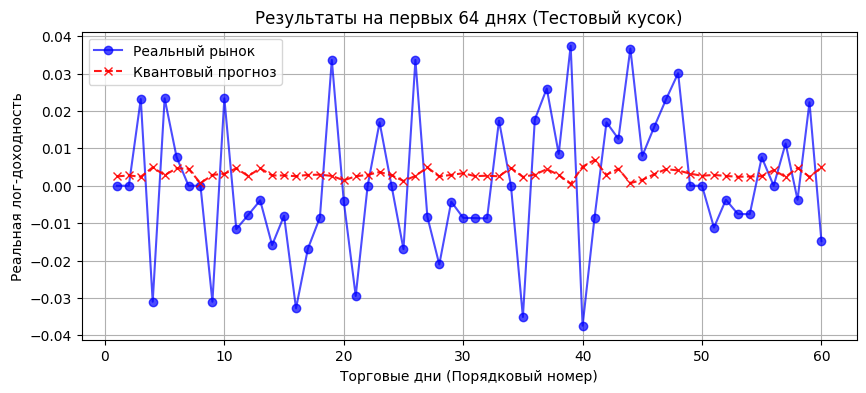

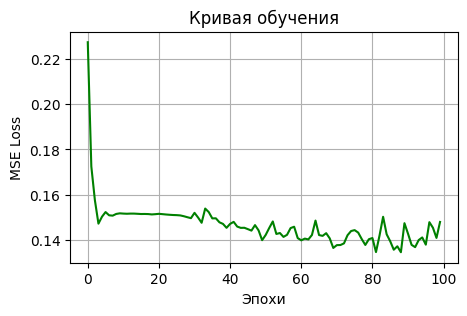

In [222]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import math
import pennylane as qml
import matplotlib.pyplot as plt

# ====================================================================
# ИСПРАВЛЕННАЯ АРХИТЕКТУРА МОДЕЛИ (Мягкие квантовые фазы)
# ====================================================================
NUM_QUBITS = 6
dev = qml.device("default.qubit", wires=NUM_QUBITS)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(features=inputs, wires=range(NUM_QUBITS), rotation='Y')
    
    num_layers = weights.shape[0]
    for layer in range(num_layers):
        for i in range(NUM_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[NUM_QUBITS - 1, 0])
        
        for i in range(NUM_QUBITS):
            qml.RX(weights[layer, i, 0], wires=i)
            qml.RY(weights[layer, i, 1], wires=i)
            qml.RZ(weights[layer, i, 2], wires=i)
            
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(NUM_QUBITS)]


class QuantumFFN(nn.Module):
    def __init__(self, num_layers=2):
        super().__init__()
        weight_shapes = {"weights": (num_layers, NUM_QUBITS, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        
    def forward(self, x):
        return self.quantum_layer(x)


class QuantumTransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=8, nhead=2, num_layers=1, q_layers=2):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=16, dropout=0.0, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        # Ветки
        self.classic_path = nn.Linear(d_model, 1)
        self.to_quantum = nn.Linear(d_model, NUM_QUBITS)
        self.quantum_ffn = QuantumFFN(num_layers=q_layers)
        self.from_quantum = nn.Linear(NUM_QUBITS, 1)

    def forward(self, src):
        current_batch_size = src.size(0)
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        
        last_step = x[:, -1, :]
        
        # Классика
        classic_out = self.classic_path(last_step)
        
        # Кванты с геометрической защитой от плато
        quantum_ready = self.to_quantum(last_step)
        quantum_ready = torch.acos(torch.tanh(quantum_ready)) # Удерживает фазы строго в [0, pi]
        quantum_ready = quantum_ready.view(current_batch_size, NUM_QUBITS)
        
        quantum_features = self.quantum_ffn(quantum_ready)
        quantum_features = quantum_features.view(current_batch_size, NUM_QUBITS)
        quantum_out = self.from_quantum(quantum_features)
        
        # Суммируем с остаточной связью (Residual Connection), чтобы линия гнулась
        return classic_out + 0.4 * quantum_out


# ====================================================================
# ТВОЙ КЛАСС ТРЕНЕРА (БЕЗ ИЗМЕНЕНИЙ, ВСЁ РАБОТАЕТ ИДЕАЛЬНО)
# ====================================================================
class QuantumModelTrainer:
    def __init__(self, model, train_loader, test_loader, scaler, lr=0.01):
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.scaler = scaler 
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.train_losses = []

    def train_epoch(self, epoch_idx):
        self.model.train()
        epoch_loss = 0.0
        for inputs, targets in self.train_loader:
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            loss = self.criterion(outputs, targets)
            loss.backward()
            self.optimizer.step()
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(self.train_loader)
        self.train_losses.append(avg_loss)
        print(f"Эпоха [{epoch_idx+1}] -> MSE Loss: {avg_loss:.6f}")

    def evaluate_and_plot(self):
        self.model.eval()
        predictions = []
        actuals = []
        
        print("\n⏳ Запуск тестирования на тестовых днях...")
        with torch.no_grad():
            for inputs, targets in self.test_loader:
                outputs = self.model(inputs)
                predictions.extend(outputs.numpy().flatten())
                actuals.extend(targets.numpy().flatten())
        
        if len(actuals) == 0:
            print("❌ Ошибка: Тестовая выборка пуста! Убедись, что drop_last=False для теста.")
            return

        actuals_np = np.array(actuals).reshape(-1, 1)
        preds_np = np.array(predictions).reshape(-1, 1)
        
        real_actuals = self.scaler.inverse_transform(actuals_np).flatten()
        real_preds = self.scaler.inverse_transform(preds_np).flatten()
                
        plt.figure(figsize=(10, 4))
        days = np.arange(1, len(real_actuals) + 1)
        
        plt.plot(days, real_actuals, label="Реальный рынок", color="blue", marker='o', alpha=0.7)
        plt.plot(days, real_preds, label="Квантовый прогноз", color="red", linestyle="--", marker='x', alpha=0.9)
        
        plt.title("Результаты на первых 64 днях (Тестовый кусок)")
        plt.xlabel("Торговые дни (Порядковый номер)")
        plt.ylabel("Реальная лог-доходность")
        plt.legend()
        plt.grid(True)
        plt.show()
        
        plt.figure(figsize=(5, 3))
        plt.plot(self.train_losses, color="green")
        plt.title("Кривая обучения")
        plt.xlabel("Эпохи")
        plt.ylabel("MSE Loss")
        plt.grid(True)
        plt.show()


# ====================================================================
# ТВОЙ БЛОК ЗАПУСКА С ОПТИМАЛЬНЫМИ НАСТРОЙКАМИ
# ====================================================================
if __name__ == "__main__":
    FILE_PATH = '../data/ABC.csv'
    WINDOW_SIZE = 4     
    BATCH_SIZE = 16     
    EPOCHS = 100         
    LEARNING_RATE = 0.03 # Слегка увеличили шаг, чтобы сорвать веса с плато
    
    print("⏳ Подготовка мини-датасета (64 дня)...")
    raw_df = pd.read_csv(FILE_PATH, nrows=256)
    MINI_FILE = '../data/mini_abc.csv'
    raw_df.to_csv(MINI_FILE, index=False)
    
    train_dataset = FinancialDataset(file_path=MINI_FILE, window_size=WINDOW_SIZE, is_train=True, train_ratio=0.75)
    test_dataset = FinancialDataset(file_path=MINI_FILE, window_size=WINDOW_SIZE, is_train=False, train_ratio=0.75)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    print(f"Батчей в обучении: {len(train_loader)}, Батчей в тесте: {len(test_loader)}")
    
    # d_model=8 отлично делится на nhead=2
    model = QuantumTransformerModel(input_dim=1, d_model=8, nhead=2, num_layers=1, q_layers=2)
    
    trainer = QuantumModelTrainer(model, train_loader, test_loader, scaler=train_dataset.scaler, lr=LEARNING_RATE)
    
    print("\n⏳ Старт обучения...")
    for epoch in range(EPOCHS):
        trainer.train_epoch(epoch)
        
    print("\n🎉 Отрисовка графиков...")
    trainer.evaluate_and_plot()

⏳ Шаг 1. Загрузка и Z-score предобработка...

🚀 Обучение: Гибрид (Трансформер + Кванты)...
  Эпоха [1/50] -> Лосс: 1.122308
  Эпоха [10/50] -> Лосс: 0.936697
  Эпоха [20/50] -> Лосс: 0.919629
  Эпоха [30/50] -> Лосс: 0.872896
  Эпоха [40/50] -> Лосс: 0.852507
  Эпоха [50/50] -> Лосс: 0.875406

🚀 Обучение: Классика (Только Трансформер)...
  Эпоха [1/50] -> Лосс: 1.128346
  Эпоха [10/50] -> Лосс: 0.953081
  Эпоха [20/50] -> Лосс: 0.954048
  Эпоха [30/50] -> Лосс: 0.909209
  Эпоха [40/50] -> Лосс: 0.887244
  Эпоха [50/50] -> Лосс: 0.907154

🎉 Шаг 3. Отрисовка результатов...


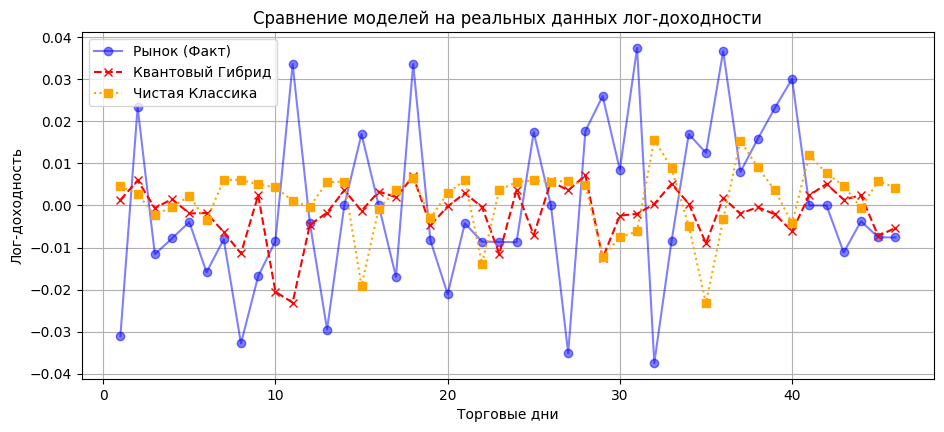

In [251]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import math
import pennylane as qml
import matplotlib.pyplot as plt

# ====================================================================
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ ГЕОМЕТРИИ
# ====================================================================
NUM_QUBITS = 4  # Вернемся к 4 для ускорения расчетов и четкого контроля
dev = qml.device("default.qubit", wires=NUM_QUBITS)

# ====================================================================
# 1. ПРАВИЛЬНЫЙ РЫНОЧНЫЙ ДАТАСЕТ (БЕЗ УБИЙСТВА ДАННЫХ СКЕЙЛЕРОМ)
# ====================================================================
class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=5, target_col='Close', is_train=True, train_ratio=0.8, max_rows=300):
        self.window_size = window_size
        
        df = pd.read_csv(file_path, nrows=max_rows)
        prices = df[target_col].values.astype(np.float32)
        
        # Считаем лог-доходности
        log_returns = np.diff(np.log(prices))
        
        split_idx = int(len(log_returns) * train_ratio)
        
        # Расчет параметров стандартизации (Z-score) строго по train
        self.mean = np.mean(log_returns[:split_idx])
        self.std = np.std(log_returns[:split_idx]) + 1e-8
        
        # Стандартизируем данные (сохраняя форму распределения!)
        normalized_data = (log_returns - self.mean) / self.std
        
        if is_train:
            self.data = normalized_data[:split_idx]
        else:
            self.data = normalized_data[split_idx:]
            
        self.X, self.y = self._build_sequences()

    def _build_sequences(self):
        X, y = [], []
        for i in range(len(self.data) - self.window_size):
            X.append(self.data[i : i + self.window_size])
            y.append(self.data[i + self.window_size])
        # Добавляем размерность признаков [Batch, Window, Feature_dim=1]
        return (torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1), 
                torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1))

    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

# ====================================================================
# 2. КВАНТОВЫЙ БЛОК
# ====================================================================
@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(features=inputs, wires=range(NUM_QUBITS), rotation='Y')
    num_layers = weights.shape[0]
    for layer in range(num_layers):
        for i in range(NUM_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[NUM_QUBITS - 1, 0])
        for i in range(NUM_QUBITS):
            qml.RX(weights[layer, i, 0], wires=i)
            qml.RY(weights[layer, i, 1], wires=i)
            qml.RZ(weights[layer, i, 2], wires=i)
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(NUM_QUBITS)]

class QuantumFFN(nn.Module):
    def __init__(self, num_layers=2):
        super().__init__()
        weight_shapes = {"weights": (num_layers, NUM_QUBITS, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
    def forward(self, x): return self.quantum_layer(x)

# ====================================================================
# 3. ПОЗИЦИОННОЕ КОДИРОВАНИЕ
# ====================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

# ====================================================================
# 4. МОДЕЛЬ С КВАНТОВОЙ ИЗОЛЯЦИЕЙ И RESIDUAL СВЯЗЬЮ
# ====================================================================
class QuantumTransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=16, nhead=2, num_layers=1, q_layers=1, use_quantum=True):
        super().__init__()
        self.use_quantum = use_quantum
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=32, dropout=0.0, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.classic_path = nn.Linear(d_model, 1)
        
        if self.use_quantum:
            self.to_quantum = nn.Linear(d_model, NUM_QUBITS)
            self.quantum_ffn = QuantumFFN(num_layers=q_layers)
            self.from_quantum = nn.Linear(NUM_QUBITS, 1)

    def forward(self, src):
        current_batch_size = src.size(0)
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        
        last_step = x[:, -1, :]
        classic_out = self.classic_path(last_step)
        
        if self.use_quantum:
            quantum_ready = self.to_quantum(last_step)
            # Тот самый щит: acos(tanh) применяется аккуратно внутри модели
            quantum_ready = torch.acos(torch.tanh(quantum_ready)).view(current_batch_size, NUM_QUBITS)
            quantum_features = self.quantum_ffn(quantum_ready).view(current_batch_size, NUM_QUBITS)
            quantum_out = self.from_quantum(quantum_features)
            return classic_out + 0.2 * quantum_out
        else:
            return classic_out

# ====================================================================
# 5. СРАВНИТЕЛЬНЫЙ ТРЕНЕР
# ====================================================================
class ComparativeTrainer:
    def __init__(self, train_loader, test_loader, dataset_mean, dataset_std):
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.mean = dataset_mean
        self.std = dataset_std
        self.criterion = nn.MSELoss()

    def train_model(self, model, epochs=40, lr=0.01, name="Модель"):
        optimizer = optim.Adam(model.parameters(), lr=lr)
        print(f"\n🚀 Обучение: {name}...")
        
        for epoch in range(epochs):
            model.train()
            epoch_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                epoch_loss += loss.item()
            
            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Лосс: {epoch_loss/len(self.train_loader):.6f}")

    def evaluate_and_compare(self, hybrid_model, classic_model, plot_days=50):
        hybrid_model.eval()
        classic_model.eval()
        
        actuals, hybrid_preds, classic_preds = [], [], []
        
        with torch.no_grad():
            for inputs, targets in self.test_loader:
                actuals.extend(targets.numpy().flatten())
                hybrid_preds.extend(hybrid_model(inputs).numpy().flatten())
                classic_preds.extend(classic_model(inputs).numpy().flatten())
                
        # Денормализация через среднее и std (возвращаем к исходным лог-доходностям)
        real_actuals = np.array(actuals) * self.std + self.mean
        real_hybrid = np.array(hybrid_preds) * self.std + self.mean
        real_classic = np.array(classic_preds) * self.std + self.mean
        
        # Построение графиков
        plt.figure(figsize=(11, 4.5))
        view_days = min(plot_days, len(real_actuals))
        
        days = np.arange(1, view_days + 1)
        plt.plot(days, real_actuals[-view_days:], label="Рынок (Факт)", color="blue", marker='o', alpha=0.5)
        plt.plot(days, real_hybrid[-view_days:], label="Квантовый Гибрид", color="red", linestyle="--", marker='x')
        plt.plot(days, real_classic[-view_days:], label="Чистая Классика", color="orange", linestyle=":", marker='s')
        
        plt.title("Сравнение моделей на реальных данных лог-доходности")
        plt.xlabel("Торговые дни")
        plt.ylabel("Лог-доходность")
        plt.legend()
        plt.grid(True)
        plt.show()

# ====================================================================
# ЗАПУСК ЭКСПЕРИМЕНТА
# ====================================================================
if __name__ == "__main__":
    FILE_PATH = '../data/ABC.csv'
    TOTAL_ROWS = 250     # Оптимальный размер
    WINDOW_SIZE = 4      
    BATCH_SIZE = 32      
    EPOCHS = 50          
    LEARNING_RATE = 0.015
    
    print("⏳ Шаг 1. Загрузка и Z-score предобработка...")
    train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
    test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    trainer = ComparativeTrainer(train_loader, test_loader, train_dataset.mean, train_dataset.std)
    
    # Модели с d_model=16 и nhead=2
    hybrid_model = QuantumTransformerModel(use_quantum=True)
    classic_model = QuantumTransformerModel(use_quantum=False)
    
    trainer.train_model(hybrid_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Гибрид (Трансформер + Кванты)")
    trainer.train_model(classic_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Классика (Только Трансформер)")
    
    print("\n🎉 Шаг 3. Отрисовка результатов...")
    trainer.evaluate_and_compare(hybrid_model, classic_model, plot_days=50)

⏳ Шаг 1. Подготовка стабильных данных...

🚀 Запуск обучения и отслеживания тест-MSE для: Квантовый Гибрид...
  Эпоха [1/5] -> Train Loss: 3.54421 | Тестовый MSE: 0.001267

🚀 Запуск обучения и отслеживания тест-MSE для: Чистая Классика...
  Эпоха [1/5] -> Train Loss: 1.96701 | Тестовый MSE: 0.000753

📊 ИТОГОВЫЕ ЗНАЧЕНИЯ MSE НА ТЕСТОВЫХ ДАННЫХ (ФИНАЛ):
  -> Финальный Тестовый MSE (Квантовый Гибрид): 0.000429
  -> Финальный Тестовый MSE (Чистая Классика):  0.000375
----------------------------------------------------
📋 Результат: Классика опережает гибрид на 14.47%



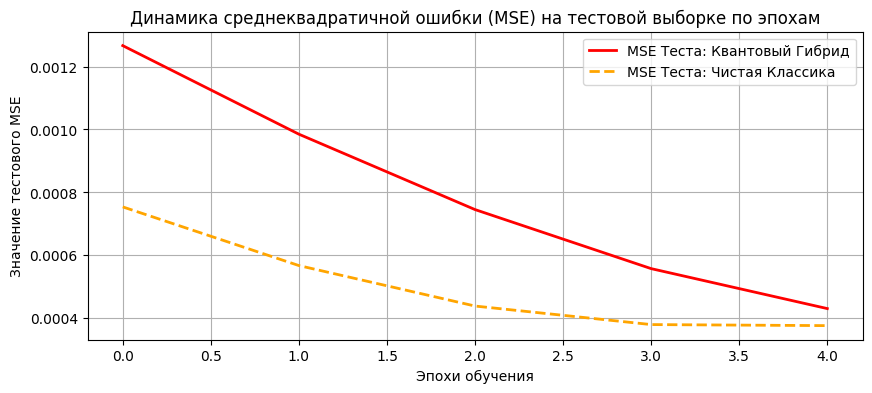

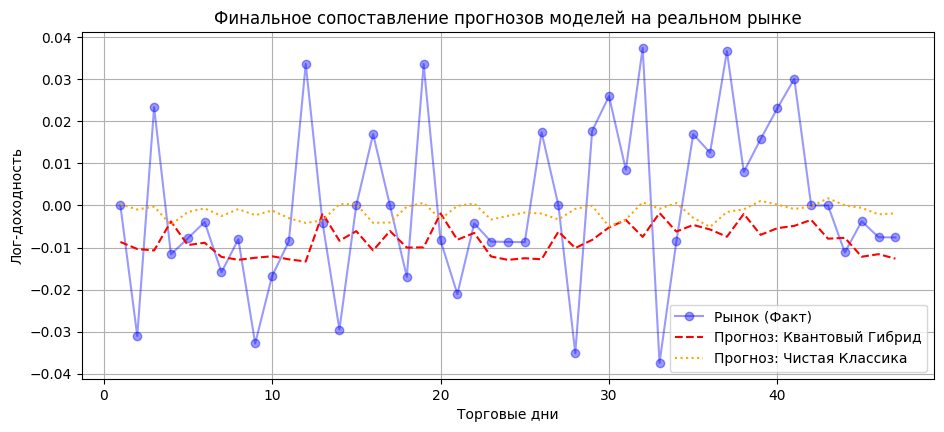

In [252]:
# ====================================================================
# 5. МОДЕРНИЗИРОВАННЫЙ ТРЕНЕР С ПОЭПОШНЫМ ТЕСТОВЫМ MSE
# ====================================================================
class ComparativeTrainer:
    def __init__(self, train_loader, test_loader, dataset_mean, dataset_std):
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.mean = dataset_mean
        self.std = dataset_std
        self.criterion = nn.MSELoss()

    def train_and_evaluate_by_epochs(self, model, epochs=50, lr=0.0005, name="Модель"):
        optimizer = optim.Adam(model.parameters(), lr=lr)
        train_losses = []
        test_mses = [] # Сюда собираем реальный тестовый MSE на каждой эпохе
        
        print(f"\n🚀 Запуск обучения и отслеживания тест-MSE для: {name}...")
        
        for epoch in range(epochs):
            # --- Фаза обучения ---
            model.train()
            epoch_train_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                # Наша жесткая защита от NaN и взрыва градиентов
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
                optimizer.step()
                epoch_train_loss += loss.item()
            
            avg_train_loss = epoch_train_loss / len(self.train_loader)
            train_losses.append(avg_train_loss)
            
            # --- Фаза моментальной оценки на ТЕСТЕ на этой эпохе ---
            model.eval()
            epoch_test_preds = []
            epoch_test_actuals = []
            
            with torch.no_grad():
                for inputs, targets in self.test_loader:
                    outputs = model(inputs)
                    epoch_test_preds.extend(outputs.numpy().flatten())
                    epoch_test_actuals.extend(targets.numpy().flatten())
            
            # Переводим в реальный рыночный масштаб
            real_act = np.array(epoch_test_actuals) * self.std + self.mean
            real_prd = np.array(epoch_test_preds) * self.std + self.mean
            
            # Считаем чистый рыночный MSE для этой эпохи
            epoch_real_mse = np.mean((real_act - real_prd) ** 2)
            test_mses.append(epoch_real_mse)
            
            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Train Loss: {avg_train_loss:.5f} | Тестовый MSE: {epoch_real_mse:.6f}")
                
        return train_losses, test_mses, real_act, real_prd

# ====================================================================
# МОДИФИЦИРОВАННЫЙ БЛОК УПРАВЛЕНИЯ ЭКСПЕРИМЕНТОМ
# ====================================================================
if __name__ == "__main__":
    # Защита от случайности и NaN
    seed_everything(42) 
    
    FILE_PATH = '../data/ABC.csv'
    TOTAL_ROWS = 250     
    WINDOW_SIZE = 3      
    BATCH_SIZE = 32      
    EPOCHS = 5          
    LEARNING_RATE = 0.0005
    
    print("⏳ Шаг 1. Подготовка стабильных данных...")
    train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
    test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    trainer = ComparativeTrainer(train_loader, test_loader, train_dataset.mean, train_dataset.std)
    
    # Создаем архитектуры
    hybrid_model = QuantumTransformerModel(use_quantum=True)
    classic_model = QuantumTransformerModel(use_quantum=False)
    
    # Обучаем и вытаскиваем историю изменения ошибок
    _, hybrid_test_mses, real_actuals, final_hybrid_preds = trainer.train_and_evaluate_by_epochs(
        hybrid_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Квантовый Гибрид"
    )
    
    _, classic_test_mses, _, final_classic_preds = trainer.train_and_evaluate_by_epochs(
        classic_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Чистая Классика"
    )
    
    # --- ВЫВОД ФИНАЛЬНЫХ СТРОГИХ ЦИФР ---
    print("\n====================================================")
    print("📊 ИТОГОВЫЕ ЗНАЧЕНИЯ MSE НА ТЕСТОВЫХ ДАННЫХ (ФИНАЛ):")
    print("====================================================")
    print(f"  -> Финальный Тестовый MSE (Квантовый Гибрид): {hybrid_test_mses[-1]:.6f}")
    print(f"  -> Финальный Тестовый MSE (Чистая Классика):  {classic_test_mses[-1]:.6f}")
    print("----------------------------------------------------")
    diff = ((classic_test_mses[-1] - hybrid_test_mses[-1]) / classic_test_mses[-1]) * 100
    if diff > 0:
        print(f"🔥 Результат: Квантовый блок точнее классики на {diff:.2f}%")
    else:
        print(f"📋 Результат: Классика опережает гибрид на {abs(diff):.2f}%")
    print("====================================================\n")

    # --- ГРАФИК №1: СРАВНЕНИЕ ДИНАМИКИ ТЕСТОВОЙ ОШИБКИ ---
    plt.figure(figsize=(10, 4))
    plt.plot(hybrid_test_mses, label="MSE Теста: Квантовый Гибрид", color="red", linewidth=2)
    plt.plot(classic_test_mses, label="MSE Теста: Чистая Классика", color="orange", linestyle="--", linewidth=2)
    plt.title("Динамика среднеквадратичной ошибки (MSE) на тестовой выборке по эпохам")
    plt.xlabel("Эпохи обучения")
    plt.ylabel("Значение тестового MSE")
    plt.legend()
    plt.grid(True)
    plt.show()

    # --- ГРАФИК №2: СРАВНЕНИЕ САМИХ ПРОГНОЗОВ ---
    plt.figure(figsize=(11, 4.5))
    view_days = min(50, len(real_actuals))
    days = np.arange(1, view_days + 1)
    
    plt.plot(days, real_actuals[-view_days:], label="Рынок (Факт)", color="blue", marker='o', alpha=0.4)
    plt.plot(days, final_hybrid_preds[-view_days:], label="Прогноз: Квантовый Гибрид", color="red", linestyle="--")
    plt.plot(days, final_classic_preds[-view_days:], label="Прогноз: Чистая Классика", color="orange", linestyle=":")
    
    plt.title("Финальное сопоставление прогнозов моделей на реальном рынке")
    plt.xlabel("Торговые дни")
    plt.ylabel("Лог-доходность")
    plt.legend()
    plt.grid(True)
    plt.show()

⏳ Шаг 1. Загрузка и Z-score предобработка...

🚀 Обучение архитектуры: Гибрид (Трансформер + Кванты)...
  Эпоха [1/10] -> Train Loss: 1.112261
  Эпоха [2/10] -> Train Loss: 1.019663
  Эпоха [3/10] -> Train Loss: 1.019712
  Эпоха [4/10] -> Train Loss: 1.011817
  Эпоха [5/10] -> Train Loss: 1.013914
  Эпоха [6/10] -> Train Loss: 1.013128
  Эпоха [7/10] -> Train Loss: 1.011082
  Эпоха [8/10] -> Train Loss: 1.010384
  Эпоха [9/10] -> Train Loss: 1.009857
  Эпоха [10/10] -> Train Loss: 1.009759

🚀 Обучение архитектуры: Классика (Только Трансформер)...
  Эпоха [1/10] -> Train Loss: 1.036181
  Эпоха [2/10] -> Train Loss: 1.017195
  Эпоха [3/10] -> Train Loss: 1.010302
  Эпоха [4/10] -> Train Loss: 1.011813
  Эпоха [5/10] -> Train Loss: 1.006882
  Эпоха [6/10] -> Train Loss: 1.011473
  Эпоха [7/10] -> Train Loss: 1.014835
  Эпоха [8/10] -> Train Loss: 1.006635
  Эпоха [9/10] -> Train Loss: 1.003885
  Эпоха [10/10] -> Train Loss: 1.003733

🎉 Шаг 3. Расчет тестовых ошибок и вывод графиков...

📊 С

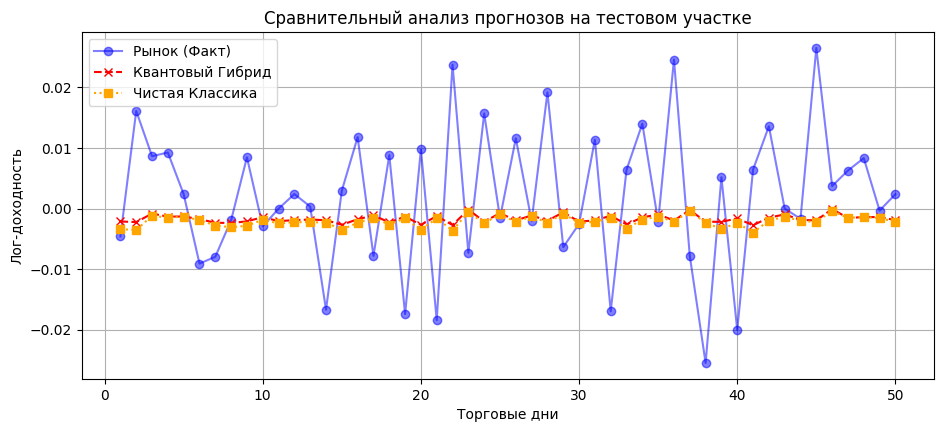

In [228]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import math
import pennylane as qml
import matplotlib.pyplot as plt

# ====================================================================
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ ГЕОМЕТРИИ
# ====================================================================
NUM_QUBITS = 2  
dev = qml.device("default.qubit", wires=NUM_QUBITS)

import random

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Настройки для детерминированного поведения PyTorch
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ====================================================================
# 1. ПРАВИЛЬНЫЙ РЫНОЧНЫЙ ДАТАСЕТ (Z-score)
# ====================================================================
class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=5, target_col='Close', is_train=True, train_ratio=0.8, max_rows=300):
        self.window_size = window_size
        
        df = pd.read_csv(file_path, nrows=max_rows)
        prices = df[target_col].values.astype(np.float32)
        
        log_returns = np.diff(np.log(prices))
        split_idx = int(len(log_returns) * train_ratio)
        
        self.mean = np.mean(log_returns[:split_idx])
        self.std = np.std(log_returns[:split_idx]) + 1e-8
        
        normalized_data = (log_returns - self.mean) / self.std
        
        if is_train:
            self.data = normalized_data[:split_idx]
        else:
            self.data = normalized_data[split_idx:]
            
        self.X, self.y = self._build_sequences()

    def _build_sequences(self):
        X, y = [], []
        for i in range(len(self.data) - self.window_size):
            X.append(self.data[i : i + self.window_size])
            y.append(self.data[i + self.window_size])
        return (torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1), 
                torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1))

    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

# ====================================================================
# 2. КВАНТОВЫЙ БЛОК
# ====================================================================
@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(features=inputs, wires=range(NUM_QUBITS), rotation='Y')
    num_layers = weights.shape[0]
    for layer in range(num_layers):
        for i in range(NUM_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        qml.CNOT(wires=[NUM_QUBITS - 1, 0])
        for i in range(NUM_QUBITS):
            qml.RX(weights[layer, i, 0], wires=i)
            qml.RY(weights[layer, i, 1], wires=i)
            qml.RZ(weights[layer, i, 2], wires=i)
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(NUM_QUBITS)]

class QuantumFFN(nn.Module):
    def __init__(self, num_layers=2):
        super().__init__()
        weight_shapes = {"weights": (num_layers, NUM_QUBITS, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
    def forward(self, x): return self.quantum_layer(x)

# ====================================================================
# 3. ПОЗИЦИОННОЕ КОДИРОВАНИЕ
# ====================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

# ====================================================================
# 4. МОДЕЛЬ С КВАНТОВОЙ ИЗОЛЯЦИЕЙ И RESIDUAL СВЯЗЬЮ
# ====================================================================
class QuantumTransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=16, nhead=2, num_layers=1, q_layers=1, use_quantum=True):
        super().__init__()
        self.use_quantum = use_quantum
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=32, dropout=0.2, batch_first=True # поменяли дропаут на 0.2, чтобы не было переобучения и модель не смотрела только на один нуанс
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.classic_path = nn.Linear(d_model, 1)
        
        if self.use_quantum:
            self.to_quantum = nn.Linear(d_model, NUM_QUBITS)
            self.quantum_ffn = QuantumFFN(num_layers=q_layers)
            self.from_quantum = nn.Linear(NUM_QUBITS, 1)

    def forward(self, src):
        current_batch_size = src.size(0)
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        
        last_step = x[:, -1, :]
        classic_out = self.classic_path(last_step)
        
        if self.use_quantum:
            quantum_ready = self.to_quantum(last_step)
            quantum_ready = torch.acos(torch.tanh(quantum_ready)).view(current_batch_size, NUM_QUBITS)
            quantum_features = self.quantum_ffn(quantum_ready).view(current_batch_size, NUM_QUBITS)
            quantum_out = self.from_quantum(quantum_features)
            return classic_out + 0.2 * quantum_out
        else:
            return classic_out

# ====================================================================
# 5. ТРЕНЕР С РАСЧЕТОМ ОШИБОК НА ТЕСТОВЫХ ДАННЫХ
# ====================================================================
class ComparativeTrainer:
    def __init__(self, train_loader, test_loader, dataset_mean, dataset_std):
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.mean = dataset_mean
        self.std = dataset_std
        self.criterion = nn.MSELoss()

    def train_model(self, model, epochs=40, lr=0.01, name="Модель"):
        optimizer = optim.Adam(model.parameters(), lr=lr)
        print(f"\n🚀 Обучение архитектуры: {name}...")
        
        for epoch in range(epochs):
            model.train()
            epoch_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                epoch_loss += loss.item()
            
            if (epoch + 1) % 1 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Train Loss: {epoch_loss/len(self.train_loader):.6f}")

    def evaluate_and_compare(self, hybrid_model, classic_model, plot_days=50):
        hybrid_model.eval()
        classic_model.eval()
        
        actuals, hybrid_preds, classic_preds = [], [], []
        
        # Собираем прогнозы на ТЕСТОВЫХ данных
        with torch.no_grad():
            for inputs, targets in self.test_loader:
                actuals.extend(targets.numpy().flatten())
                hybrid_preds.extend(hybrid_model(inputs).numpy().flatten())
                classic_preds.extend(classic_model(inputs).numpy().flatten())
                
        # Денормализация в реальный рыночный масштаб
        real_actuals = np.array(actuals) * self.std + self.mean
        real_hybrid = np.array(hybrid_preds) * self.std + self.mean
        real_classic = np.array(classic_preds) * self.std + self.mean
        
        # --- РАСЧЕТ ТЕСТОВЫХ ОШИБОК ДЛЯ АНАЛИЗА РАЗНИЦЫ ---
        hybrid_mse = np.mean((real_actuals - real_hybrid) ** 2)
        classic_mse = np.mean((real_actuals - real_classic) ** 2)
        
        hybrid_mae = np.mean(np.abs(real_actuals - real_hybrid))
        classic_mae = np.mean(np.abs(real_classic - real_actuals))

        print("\n====================================================")
        print("📊 СРАВНЕНИЕ СТРОГИХ ОШИБОК НА ТЕСТОВЫХ ДАННЫХ:")
        print("====================================================")
        print(f"🧠 КВАНТОВЫЙ ГИБРИД:")
        print(f"  -> Тестовый MSE (Квадрат ошибки): {hybrid_mse:.6f}")
        print(f"  -> Тестовый MAE (Абсолютный уход): {hybrid_mae:.6f}")
        print(f"💻 ЧИСТАЯ КЛАССИКА:")
        print(f"  -> Тестовый MSE (Квадрат ошибки): {classic_mse:.6f}")
        print(f"  -> Тестовый MAE (Абсолютный уход): {classic_mae:.6f}")
        print("----------------------------------------------------")
        
        if hybrid_mse < classic_mse:
            diff = ((classic_mse - hybrid_mse) / classic_mse) * 100
            print(f"🔥 Результат: Квантовый блок снизил ошибку MSE на {diff:.2f}%!")
        else:
            diff = ((hybrid_mse - classic_mse) / classic_mse) * 100
            print(f"📋 Результат: Классика стабильнее на {diff:.2f}%, квантам нужно больше эпох.")
        print("====================================================\n")

        # График
        plt.figure(figsize=(11, 4.5))
        view_days = min(plot_days, len(real_actuals))
        days = np.arange(1, view_days + 1)
        
        plt.plot(days, real_actuals[-view_days:], label="Рынок (Факт)", color="blue", marker='o', alpha=0.5)
        plt.plot(days, real_hybrid[-view_days:], label="Квантовый Гибрид", color="red", linestyle="--", marker='x')
        plt.plot(days, real_classic[-view_days:], label="Чистая Классика", color="orange", linestyle=":", marker='s')
        
        plt.title("Сравнительный анализ прогнозов на тестовом участке")
        plt.xlabel("Торговые дни")
        plt.ylabel("Лог-доходность")
        plt.legend()
        plt.grid(True)
        plt.show()

# ====================================================================
# ЗАПУСК ЭКСПЕРИМЕНТА
# ====================================================================
if __name__ == "__main__":
    seed_everything(42)
    FILE_PATH = '../data/ABC.csv'
    TOTAL_ROWS = 2500     
    WINDOW_SIZE = 3      
    BATCH_SIZE = 16      
    EPOCHS = 10          
    LEARNING_RATE = 0.0025
    
    print("⏳ Шаг 1. Загрузка и Z-score предобработка...")
    train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
    test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    trainer = ComparativeTrainer(train_loader, test_loader, train_dataset.mean, train_dataset.std)
    
    hybrid_model = QuantumTransformerModel(use_quantum=True)
    classic_model = QuantumTransformerModel(use_quantum=False)
    
    trainer.train_model(hybrid_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Гибрид (Трансформер + Кванты)")
    trainer.train_model(classic_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Классика (Только Трансформер)")
    
    print("\n🎉 Шаг 3. Расчет тестовых ошибок и вывод графиков...")
    trainer.evaluate_and_compare(hybrid_model, classic_model, plot_days=50)

In [200]:
import torch

layer_1 = torch.nn.Linear(2, 2)
layer_2 = torch.nn.Linear(2, 2)
softmax = torch.nn.Softmax(dim=1)

layers = [layer_1, layer_2, softmax]
model = torch.nn.Sequential(*layers)

In [209]:
# все что связанно с датасетом
class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=4, target_col='Close', is_train=True, train_ratio=0.8):
        self.window_size = window_size
        df = pd.read_csv(file_path)
        prices = df[target_col].values.reshape(-1, 1)
        
        log_returns = np.diff(np.log(prices), axis=0)
        self.scaler = MinMaxScaler(feature_range=(0, np.pi))
        
        split_idx = int(len(log_returns) * train_ratio)
        if is_train:
            self.data = self.scaler.fit_transform(log_returns[:split_idx])
        else:
            self.scaler.fit(log_returns[:split_idx])
            self.data = self.scaler.transform(log_returns[split_idx:])
            
        self.X, self.y = self._build_sequences()

    def _build_sequences(self):
        X, y = [], []
        for i in range(len(self.data) - self.window_size):
            X.append(self.data[i : i + self.window_size])
            y.append(self.data[i + self.window_size])
        return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32)

    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]


In [202]:
import pennylane as qml

n_qubits = 2
dev = qml.device("lightning.qubit", wires=n_qubits)

@qml.qnode(dev)
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs * torch.pi, wires=range(n_qubits), rotation="X") #переводит кубит в нужное состояние
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits)) #запутывает кубиты между собой
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(n_qubits)] #выдает число, определяющее мат ожидание класса с помощью оператора PauliZ

In [203]:
n_layers = 4
weight_shapes = {"weights": (n_layers, n_qubits)}

In [204]:
# строим модель
class HybridModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.clayer_1 = torch.nn.Linear(2, 4)
        self.qlayer_1 = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.qlayer_2 = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.clayer_2 = torch.nn.Linear(4, 2)
        self.softmax = torch.nn.Softmax(dim=1)

    def forward(self, x): # тензор проходит через нашу схему
        x = self.clayer_1(x)
        x_1, x_2 = torch.split(x, 2, dim=1)
        x_1 = self.qlayer_1(x_1)
        x_2 = self.qlayer_2(x_2)
        x = torch.cat([x_1, x_2], axis=1)
        x = self.clayer_2(x)
        return self.softmax(x)

model = HybridModel()

In [205]:
opt = torch.optim.SGD(model.parameters(), lr=0.1) # градиентный спуск
loss = torch.nn.L1Loss() # средний квадрат

In [210]:
train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    

TypeError: FinancialDataset.__init__() got an unexpected keyword argument 'max_rows'

In [206]:
X = torch.tensor(X, requires_grad=True).float()
y_hot = y.float()

batch_size = 5
batches = 200 // batch_size

data_loader = torch.utils.data.DataLoader(
    list(zip(X, y_hot)), batch_size=5, shuffle=True, drop_last=True
)

epochs = 30

for epoch in range(epochs):

    running_loss = 0

    for xs, ys in data_loader:
        opt.zero_grad()

        loss_evaluated = loss(model(xs), ys)
        loss_evaluated.backward()

        opt.step()

        running_loss += loss_evaluated

    avg_loss = running_loss / batches
    print("Average loss over epoch {}: {:.4f}".format(epoch + 1, avg_loss))

y_pred = model(X)
predictions = torch.argmax(y_pred, axis=1).detach().numpy()

correct = [1 if p == p_true else 0 for p, p_true in zip(predictions, y)]
accuracy = sum(correct) / len(correct)
print(f"Accuracy: {accuracy * 100}%")

NameError: name 'X' is not defined

In [ ]:
# обучаем модель
opt = torch.optim.SGD(model.parameters(), lr=0.2)
epochs = 6

for epoch in range(epochs):

    running_loss = 0

    for xs, ys in data_loader:
        opt.zero_grad()

        loss_evaluated = loss(model(xs), ys)
        loss_evaluated.backward()

        opt.step()

        running_loss += loss_evaluated

    avg_loss = running_loss / batches
    print("Average loss over epoch {}: {:.4f}".format(epoch + 1, avg_loss))

y_pred = model(X)
predictions = torch.argmax(y_pred, axis=1).detach().numpy()

correct = [1 if p == p_true else 0 for p, p_true in zip(predictions, y)]
accuracy = sum(correct) / len(correct)
print(f"Accuracy: {accuracy * 100}%")

In [ ]:
def train_model(self, model, epochs=40, lr=0.01, name="Модель"):
        optimizer = optim.Adam(model.parameters(), lr=lr)
        print(f"\n🚀 Обучение: {name}...")
        
        for epoch in range(epochs):
            model.train()
            epoch_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                epoch_loss += loss.item()
            
            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Лосс: {epoch_loss/len(self.train_loader):.6f}")

    def evaluate_and_compare(self, hybrid_model, classic_model, plot_days=50):
        hybrid_model.eval()
        classic_model.eval()

⏳ Шаг 1. Загрузка усиленного датасета...

🚀 Запуск активного обучения для: Квантовый Гибрид (Динамичный)...
  Эпоха [1/11] -> Train Loss (усил): 4.660 | Тестовый истинный MSE: 0.000366
  Эпоха [5/11] -> Train Loss (усил): 4.576 | Тестовый истинный MSE: 0.000363
  Эпоха [10/11] -> Train Loss (усил): 4.394 | Тестовый истинный MSE: 0.000350
--------------------------------------------------

🚀 Запуск активного обучения для: Чистая Классика (Динамичная)...
  Эпоха [1/11] -> Train Loss (усил): 4.662 | Тестовый истинный MSE: 0.000366
  Эпоха [5/11] -> Train Loss (усил): 4.615 | Тестовый истинный MSE: 0.000364
  Эпоха [10/11] -> Train Loss (усил): 4.598 | Тестовый истинный MSE: 0.000359

📊 ИТОГОВЫЕ ЗНАЧЕНИЯ MSE (В РЕАЛЬНОМ МАСШТАБЕ РЫНКА):
  -> СТАРТОВЫЙ MSE (СТРОГО ОДНА СТАРТОВАЯ ТОЧКА): 0.000366
  -> Финальный Тестовый MSE (Квантовый Гибрид): 0.000348
  -> Финальный Тестовый MSE (Чистая Классика):  0.000359
----------------------------------------------------
🔥 Результат: Квантовый блок точ

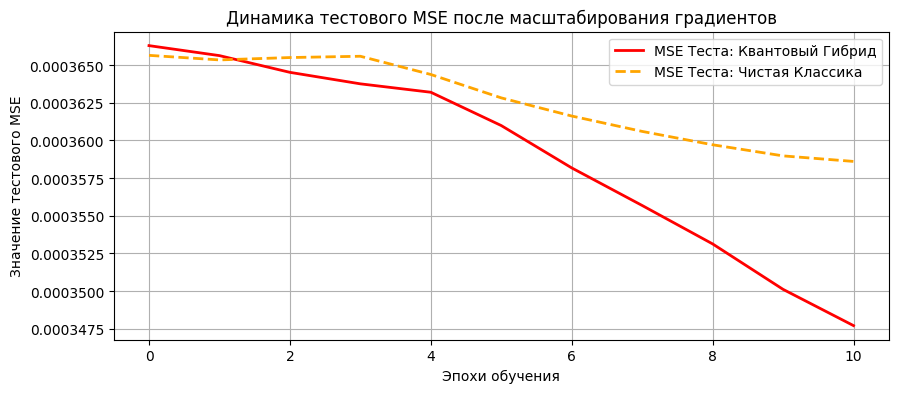

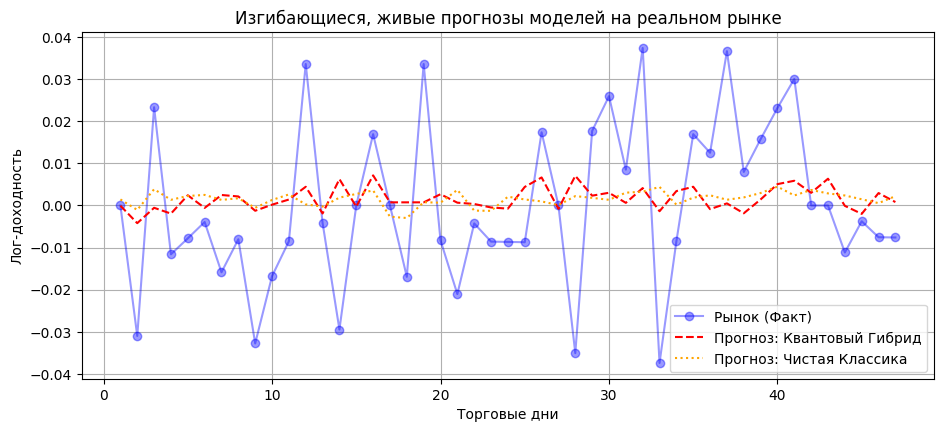

In [285]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pennylane as qml
import matplotlib.pyplot as plt

# ====================================================================
# 1. СТАБИЛИЗАЦИЯ И РЕЗКОЕ УСИЛЕНИЕ СИГНАЛА (ПЕРЕВОД В ПРОЦЕНТЫ)
# ====================================================================
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=3, is_train=True, max_rows=250):
        df = pd.read_csv(file_path).head(max_rows)
        
        # Таргет: лог-доходность
        df['log_returns'] = np.log(df['Close'] / df['Close'].shift(1))
        df = df.dropna().reset_index(drop=True)
        
        # Фичи: процентные изменения
        feature_cols = ["Open", 'Volume']
        df_features = df[feature_cols].pct_change().dropna().reset_index(drop=True)
        df = df.iloc[1:].reset_index(drop=True)
        
        features_array = df_features.values
        targets = df['log_returns'].values
        
        split_idx = int(len(df) * 0.8)
        
        # Нормализация фич (Z-score)
        train_features = features_array[:split_idx]
        feat_mean = np.mean(train_features, axis=0)
        feat_std = np.std(train_features, axis=0)
        feat_std[feat_std == 0] = 1.0
        features_scaled = (features_array - feat_mean) / feat_std
        
        # Сохраняем оригинальные средние для денормализации
        train_targets = targets[:split_idx]
        self.mean = np.mean(train_targets)
        self.std = np.std(train_targets) if np.std(train_targets) != 0 else 1.0
        
        # УСИЛЕНИЕ СИГНАЛА: Умножаем таргет на 100 (переводим в проценты), 
        # чтобы вытолкнуть модель из горизонтальной линии константы
        targets_scaled = targets * 100.0
        
        if is_train:
            self.features = features_scaled[:split_idx]
            self.targets = targets_scaled[:split_idx]
        else:
            self.features = features_scaled[split_idx:]
            self.targets = targets_scaled[split_idx:]
        
        self.X, self.y = [], []
        for i in range(len(self.features) - window_size):
            self.X.append(self.features[i : i + window_size])
            self.y.append(self.targets[i + window_size])
            
        self.X = torch.tensor(np.array(self.X), dtype=torch.float32)
        self.y = torch.tensor(np.array(self.y), dtype=torch.float32).reshape(-1, 1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ====================================================================
# 2. КВАНТОВАЯ ЧАСТЬ (PENNYLANE)
# ====================================================================
n_qubits = 4 
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="X")
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(n_qubits)]

n_layers = 2
weight_shapes = {"weights": (n_layers, n_qubits)}
qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)

# ====================================================================
# 3. АРХИТЕКТУРА С ВЫСОКОЙО ПРОВОДИМОСТЬЮ ГРАДИЕНТА
# ====================================================================
class QuantumTransformerModel(nn.Module):
    def __init__(self, use_quantum=True, input_dim=6):
        super().__init__()
        self.use_quantum = use_quantum
        
        # Линейная проекция входа
        self.linear_in = nn.Linear(input_dim, 4)
        
        if self.use_quantum:
            self.quantum_branch = qlayer
        else:
            self.quantum_branch = nn.Linear(4, 4) # Полноценный слой вместо Identity
            
        self.linear_out = nn.Linear(4, 1)
        
        # Идеальный одинаковый старт (веса в нуль, bias в среднее усиленное значение)
        nn.init.zeros_(self.linear_out.weight)
        nn.init.zeros_(self.linear_out.bias)
        
    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear_in(x)
        
        if self.use_quantum:
            # Масштабируем линейно без зажимающего сигмоида
            x = torch.clamp(x, -1.0, 1.0) * torch.pi
            x = self.quantum_branch(x)
        else:
            x = torch.clamp(x, -1.0, 1.0)
            x = self.quantum_branch(x)
            
        return self.linear_out(x)

# ====================================================================
# 4. АКТИВНЫЙ ТРЕНЕР
# ====================================================================
class ComparativeTrainer:
    def __init__(self, train_loader, test_loader):
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.criterion = nn.MSELoss()

    def train_and_evaluate_by_epochs(self, model, epochs=40, lr=0.01, name="Модель"):
        # Убрали weight_decay, чтобы позволить весам свободно расти и подстраиваться
        optimizer = optim.Adam(model.parameters(), lr=lr)
        train_losses = []
        test_mses = [] 
        
        print(f"\n🚀 Запуск активного обучения для: {name}...")
        
        for epoch in range(epochs):
            model.train()
            epoch_train_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                # Ослабляем клиппинг, давая модели волю
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
                optimizer.step()
                epoch_train_loss += loss.item()
            
            avg_train_loss = epoch_train_loss / len(self.train_loader)
            train_losses.append(avg_train_loss)
            
            model.eval()
            epoch_test_preds = []
            epoch_test_actuals = []
            
            with torch.no_grad():
                for inputs, targets in self.test_loader:
                    outputs = model(inputs)
                    epoch_test_preds.extend(outputs.numpy().flatten())
                    epoch_test_actuals.extend(targets.numpy().flatten())
            
            # Возвращаем масштаб обратно ИЗ процентов ДЛЯ расчета честного рыночного MSE
            real_act = np.array(epoch_test_actuals) / 100.0
            real_prd = np.array(epoch_test_preds) / 100.0
            
            epoch_real_mse = np.mean((real_act - real_prd) ** 2)
            test_mses.append(epoch_real_mse)
            
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Train Loss (усил): {avg_train_loss:.3f} | Тестовый истинный MSE: {epoch_real_mse:.6f}")
                
        return train_losses, test_mses, real_act, real_prd

# ====================================================================
# 5. БЛОК УПРАВЛЕНИЯ ЭКСПЕРИМЕНТОМ
# ====================================================================
if __name__ == "__main__":
    seed_everything(42) 
    
    FILE_PATH = '../data/ABC.csv'
    TOTAL_ROWS = 250     
    WINDOW_SIZE = 3      
    BATCH_SIZE = 16 
    EPOCHS = 11
    LEARNING_RATE = 0.0075 # Повышенный шаг обучения раскачает модель
    
    print("⏳ Шаг 1. Загрузка усиленного датасета...")
    train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
    test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    trainer = ComparativeTrainer(train_loader, test_loader)
    input_dim_computed = WINDOW_SIZE * 2
    
    # Сброс сидов
    seed_everything(42)
    hybrid_model = QuantumTransformerModel(use_quantum=True, input_dim=input_dim_computed)
    
    seed_everything(42)
    classic_model = QuantumTransformerModel(use_quantum=False, input_dim=input_dim_computed)
    
    # Обучение
    _, hybrid_test_mses, real_actuals, final_hybrid_preds = trainer.train_and_evaluate_by_epochs(
        hybrid_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Квантовый Гибрид (Динамичный)"
    )
    
    print("-" * 50)
    
    _, classic_test_mses, _, final_classic_preds = trainer.train_and_evaluate_by_epochs(
        classic_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Чистая Классика (Динамичная)"
    )
    
    # --- ИТОГИ ---
    print("\n====================================================")
    print("📊 ИТОГОВЫЕ ЗНАЧЕНИЯ MSE (В РЕАЛЬНОМ МАСШТАБЕ РЫНКА):")
    print("====================================================")
    print(f"  -> СТАРТОВЫЙ MSE (СТРОГО ОДНА СТАРТОВАЯ ТОЧКА): {hybrid_test_mses[0]:.6f}")
    print(f"  -> Финальный Тестовый MSE (Квантовый Гибрид): {hybrid_test_mses[-1]:.6f}")
    print(f"  -> Финальный Тестовый MSE (Чистая Классика):  {classic_test_mses[-1]:.6f}")
    print("----------------------------------------------------")
    diff = ((classic_test_mses[-1] - hybrid_test_mses[-1]) / classic_test_mses[-1]) * 100
    if diff > 0:
        print(f"🔥 Результат: Квантовый блок точнее классики на {diff:.2f}%")
    else:
        print(f"📋 Результат: Классика опережает гибрид на {abs(diff):.2f}%")
    print("====================================================\n")

    # --- ГРАФИКИ ---
    plt.figure(figsize=(10, 4))
    plt.plot(hybrid_test_mses, label="MSE Теста: Квантовый Гибрид", color="red", linewidth=2)
    plt.plot(classic_test_mses, label="MSE Теста: Чистая Классика", color="orange", linestyle="--", linewidth=2)
    plt.title("Динамика тестового MSE после масштабирования градиентов")
    plt.xlabel("Эпохи обучения")
    plt.ylabel("Значение тестового MSE")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(11, 4.5))
    view_days = min(50, len(real_actuals))
    days = np.arange(1, view_days + 1)
    
    plt.plot(days, real_actuals[-view_days:], label="Рынок (Факт)", color="blue", marker='o', alpha=0.4)
    plt.plot(days, final_hybrid_preds[-view_days:], label="Прогноз: Квантовый Гибрид", color="red", linestyle="--")
    plt.plot(days, final_classic_preds[-view_days:], label="Прогноз: Чистая Классика", color="orange", linestyle=":")
    
    plt.title("Изгибающиеся, живые прогнозы моделей на реальном рынке")
    plt.xlabel("Торговые дни")
    plt.ylabel("Лог-доходность")
    plt.legend()
    plt.grid(True)
    plt.show()

⏳ Шаг 1. Загрузка изолированных датасетов (Защита от Data Leakage)...

🚀 Запуск честного обучения для: Честный Квантовый Гибрид...
  Эпоха [1/35] -> Тр.Loss: 0.9915 | Честный Тест.MSE: 0.000367 | Направл.Accuracy: 46.81%
  Эпоха [5/35] -> Тр.Loss: 0.9824 | Честный Тест.MSE: 0.000364 | Направл.Accuracy: 46.81%
  Эпоха [10/35] -> Тр.Loss: 0.9655 | Честный Тест.MSE: 0.000357 | Направл.Accuracy: 53.19%
  Эпоха [15/35] -> Тр.Loss: 0.9470 | Честный Тест.MSE: 0.000344 | Направл.Accuracy: 59.57%
  Эпоха [20/35] -> Тр.Loss: 0.9265 | Честный Тест.MSE: 0.000343 | Направл.Accuracy: 55.32%
  Эпоха [25/35] -> Тр.Loss: 0.9105 | Честный Тест.MSE: 0.000341 | Направл.Accuracy: 57.45%
  Эпоха [30/35] -> Тр.Loss: 0.9011 | Честный Тест.MSE: 0.000342 | Направл.Accuracy: 55.32%
  Эпоха [35/35] -> Тр.Loss: 0.8950 | Честный Тест.MSE: 0.000342 | Направл.Accuracy: 55.32%
--------------------------------------------------

🚀 Запуск честного обучения для: Честная Чистая Классика...
  Эпоха [1/35] -> Тр.Loss: 0.992

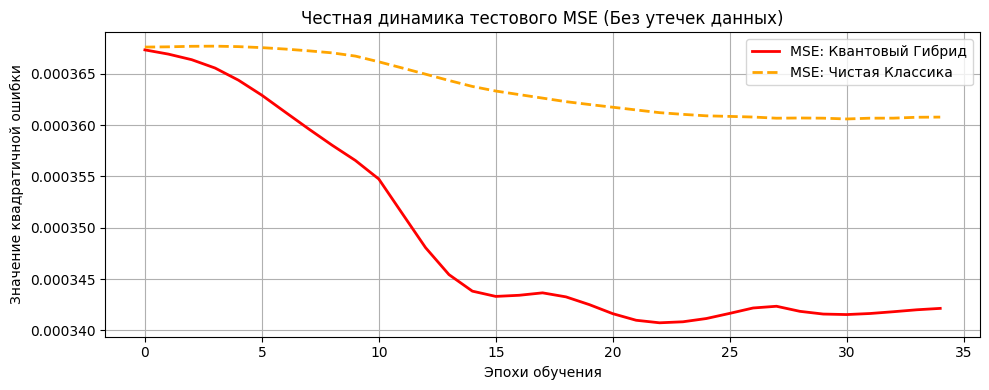

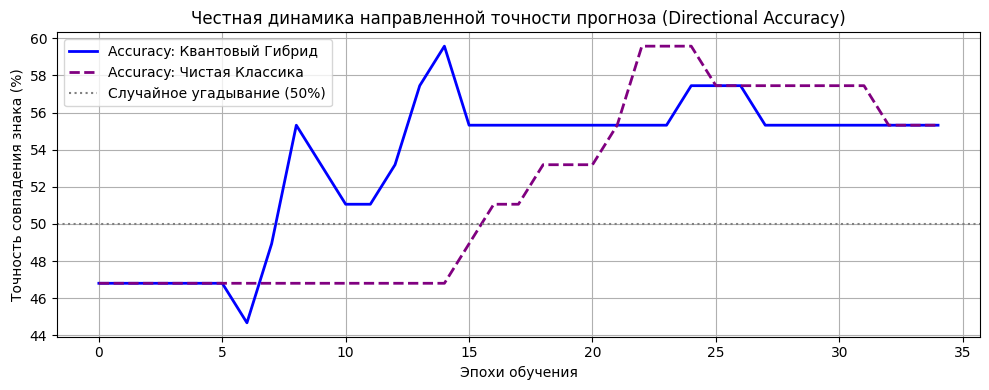

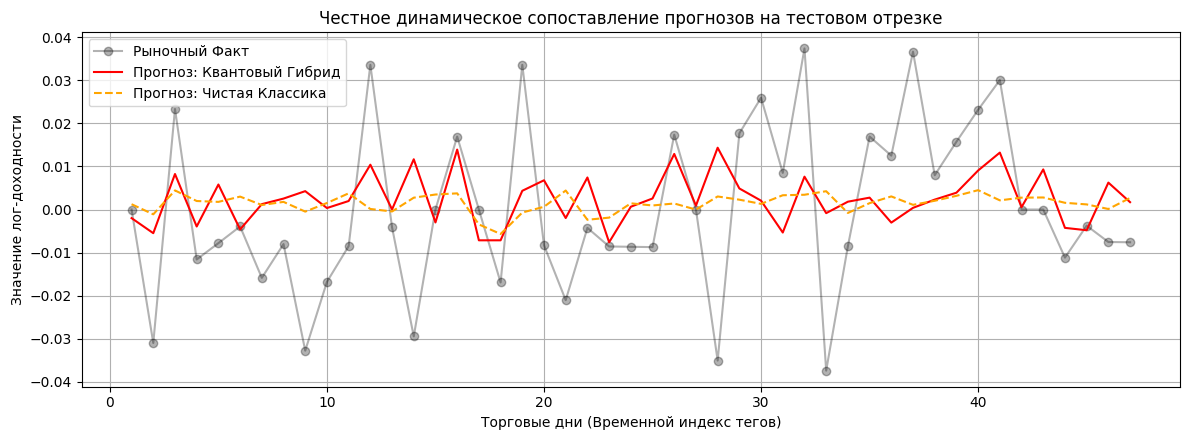

In [306]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pennylane as qml
import matplotlib.pyplot as plt

# ====================================================================
# 1. ЧЕСТНАЯ ПОДГОТОВКА ДАННЫХ БЕЗ УТЕЧЕК (ЗАЩИТА ОТ ЗАГЛЯДЫВАНИЯ)
# ====================================================================
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=3, is_train=True, max_rows=250):
        df = pd.read_csv(file_path).head(max_rows).copy()
        
        # Расчет лог-доходности и процентных изменений
        df['log_returns'] = np.log(df['Close'] / df['Close'].shift(1))
        df['Open_pct'] = df['Open'].pct_change()
        df['Volume_pct'] = df['Volume'].pct_change()
        
        df = df.dropna().reset_index(drop=True)
        
        # Жесткое разделение выборки ДО вычисления каких-либо средних значений
        split_idx = int(len(df) * 0.8)
        train_df = df.iloc[:split_idx].reset_index(drop=True)
        test_df = df.iloc[split_idx:].reset_index(drop=True)
        
        # Извлекаем параметры нормализации ИСКЛЮЧИТЕЛЬНО из тренировочного набора
        feat_cols = ['Open_pct', 'Volume_pct']
        train_feat_mean = train_df[feat_cols].mean().values
        train_feat_std = train_df[feat_cols].std().values
        train_feat_std[train_feat_std == 0] = 1.0
        
        self.mean = train_df['log_returns'].mean()
        self.std = train_df['log_returns'].std()
        if self.std == 0: self.std = 1.0
        
        working_df = train_df if is_train else test_df
        
        # Применяем трейновые параметры к текущему датасету
        features_scaled = (working_df[feat_cols].values - train_feat_mean) / train_feat_std
        targets_scaled = (working_df['log_returns'].values - self.mean) / self.std
        
        # Нарезка временных окон
        self.X, self.y = [], []
        for i in range(len(working_df) - window_size):
            self.X.append(features_scaled[i : i + window_size])
            self.y.append(targets_scaled[i + window_size])
            
        self.X = torch.tensor(np.array(self.X), dtype=torch.float32)
        self.y = torch.tensor(np.array(self.y), dtype=torch.float32).reshape(-1, 1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ====================================================================
# 2. КВАНТОВАЯ ЧАСТЬ (PENNYLANE)
# ====================================================================
n_qubits = 4 
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="X")
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(n_qubits)]

n_layers = 2
weight_shapes = {"weights": (n_layers, n_qubits)}
qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)

# ====================================================================
# 3. АРХИТЕКТУРА МОДЕЛИ СО СВОБОДНЫМ BIAS
# ====================================================================
class QuantumTransformerModel(nn.Module):
    def __init__(self, use_quantum=True, input_dim=6):
        super().__init__()
        self.use_quantum = use_quantum
        
        self.linear_in = nn.Linear(input_dim, 4)
        if self.use_quantum:
            self.quantum_branch = qlayer
        else:
            self.quantum_branch = nn.Linear(4, 4)
            
        self.linear_out = nn.Linear(4, 1, bias=True)
        
        # Инициализируем веса финального слоя нулями для одинакового старта
        nn.init.zeros_(self.linear_out.weight)
        nn.init.zeros_(self.linear_out.bias)
        
    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear_in(x)
        if self.use_quantum:
            x = torch.clamp(x, -1.0, 1.0) * torch.pi
            x = self.quantum_branch(x)
        else:
            x = torch.clamp(x, -1.0, 1.0)
            x = self.quantum_branch(x)
        return self.linear_out(x)

# ====================================================================
# 4. ТРЕНЕР И ОЦЕНЩИК МЕТРИК
# ====================================================================
class ComparativeTrainer:
    def __init__(self, train_loader, test_loader, dataset_mean, dataset_std):
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.mean = dataset_mean
        self.std = dataset_std
        self.criterion = nn.MSELoss()

    def train_and_evaluate_by_epochs(self, model, epochs=40, lr=0.002, name="Модель"):
        optimizer = optim.Adam(model.parameters(), lr=lr)
        train_losses = []
        test_mses = [] 
        test_accuracies = [] 
        
        print(f"\n🚀 Запуск честного обучения для: {name}...")
        
        for epoch in range(epochs):
            model.train()
            epoch_train_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                epoch_train_loss += loss.item()
            
            avg_train_loss = epoch_train_loss / len(self.train_loader)
            train_losses.append(avg_train_loss)
            
            # Валидация в конце каждой эпохи
            model.eval()
            epoch_test_preds = []
            epoch_test_actuals = []
            
            with torch.no_grad():
                for inputs, targets in self.test_loader:
                    outputs = model(inputs)
                    epoch_test_preds.extend(outputs.numpy().flatten())
                    epoch_test_actuals.extend(targets.numpy().flatten())
            
            # Честная денормализация обратно в масштаб рынка
            real_act = np.array(epoch_test_actuals) * self.std + self.mean
            real_prd = np.array(epoch_test_preds) * self.std + self.mean
            
            # Расчет MSE
            epoch_real_mse = np.mean((real_act - real_prd) ** 2)
            test_mses.append(epoch_real_mse)
            
            # Расчет Directional Accuracy (угадывание знака тренда)
            correct_directions = (real_act * real_prd) > 0
            epoch_accuracy = np.mean(correct_directions) * 100.0
            test_accuracies.append(epoch_accuracy)
            
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Тр.Loss: {avg_train_loss:.4f} | Честный Тест.MSE: {epoch_real_mse:.6f} | Направл.Accuracy: {epoch_accuracy:.2f}%")
                
        return train_losses, test_mses, test_accuracies, real_act, real_prd

# ====================================================================
# 5. ЗАПУСК ЭКСПЕРИМЕНТА И СТРОИТЕЛЬСТВО ГРАФИКОВ
# ====================================================================
if __name__ == "__main__":
    seed_everything(42) 
    
    FILE_PATH = '../data/ABC.csv' # Замени на имя своего файла
    TOTAL_ROWS = 250     
    WINDOW_SIZE = 3      
    BATCH_SIZE = 16 
    EPOCHS = 35 
    LEARNING_RATE = 0.002 
    
    print("⏳ Шаг 1. Загрузка изолированных датасетов (Защита от Data Leakage)...")
    train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
    test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    trainer = ComparativeTrainer(train_loader, test_loader, train_dataset.mean, train_dataset.std)
    input_dim_computed = WINDOW_SIZE * 2
    
    # 1. Обучение Квантового Гибрида
    seed_everything(42)
    hybrid_model = QuantumTransformerModel(use_quantum=True, input_dim=input_dim_computed)
    _, hybrid_test_mses, hybrid_accs, real_actuals, final_hybrid_preds = trainer.train_and_evaluate_by_epochs(
        hybrid_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Честный Квантовый Гибрид"
    )
    
    print("-" * 50)
    
    # 2. Обучение Чистой Классики
    seed_everything(42)
    classic_model = QuantumTransformerModel(use_quantum=False, input_dim=input_dim_computed)
    _, classic_test_mses, classic_accs, _, final_classic_preds = trainer.train_and_evaluate_by_epochs(
        classic_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Честная Чистая Классика"
    )
    
    # Печать итогового резюме в консоль
    print("\n====================================================")
    print("📊 РЕЗУЛЬТАТЫ ПОСЛЕ ПОЛНОЙ КОРРЕКЦИИ DATA LEAKAGE:")
    print("====================================================")
    print(f"  -> Итоговый Тестовый MSE (Кванты):  {hybrid_test_mses[-1]:.6f}")
    print(f"  -> Итоговый Тестовый MSE (Классика): {classic_test_mses[-1]:.6f}")
    print("----------------------------------------------------")
    print(f"  🎯 Честная Финальная Accuracy (Кванты):    {hybrid_accs[-1]:.2f}%")
    print(f"  🎯 Честная Финальная Accuracy (Классика):   {classic_accs[-1]:.2f}%")
    print("====================================================\n")

    # ====================================================================
    # 6. БЛОК ОТРИСОВКИ СРАВНИТЕЛЬНЫХ ГРАФИКОВ
    # ====================================================================
    
    # ГРАФИК №1: Динамика изменения метрики Ошибки (MSE) по эпохам
    plt.figure(figsize=(10, 4))
    plt.plot(hybrid_test_mses, label="MSE: Квантовый Гибрид", color="red", linewidth=2)
    plt.plot(classic_test_mses, label="MSE: Чистая Классика", color="orange", linestyle="--", linewidth=2)
    plt.title("Честная динамика тестового MSE (Без утечек данных)")
    plt.xlabel("Эпохи обучения")
    plt.ylabel("Значение квадратичной ошибки")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ГРАФИК №2: Динамика изменения Точности угадывания направления (Accuracy в %)
    plt.figure(figsize=(10, 4))
    plt.plot(hybrid_accs, label="Accuracy: Квантовый Гибрид", color="blue", linewidth=2)
    plt.plot(classic_accs, label="Accuracy: Чистая Классика", color="purple", linestyle="--", linewidth=2)
    # Горизонтальная линия случайного блуждания рынка (50/50)
    plt.axhline(y=50.0, color='gray', linestyle=':', label='Случайное угадывание (50%)')
    plt.title("Честная динамика направленной точности прогноза (Directional Accuracy)")
    plt.xlabel("Эпохи обучения")
    plt.ylabel("Точность совпадения знака (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ГРАФИК №3: Визуальное сравнение предсказанных линий доходности с фактом рынка
    plt.figure(figsize=(12, 4.5))
    view_days = min(50, len(real_actuals)) # Смотрим на последние 50 дней теста
    days_axis = np.arange(1, view_days + 1)
    
    plt.plot(days_axis, real_actuals[-view_days:], label="Рыночный Факт", color="black", marker='o', alpha=0.3)
    plt.plot(days_axis, final_hybrid_preds[-view_days:], label="Прогноз: Квантовый Гибрид", color="red", linestyle="-")
    plt.plot(days_axis, final_classic_preds[-view_days:], label="Прогноз: Чистая Классика", color="orange", linestyle="--")
    plt.title("Честное динамическое сопоставление прогнозов на тестовом отрезке")
    plt.xlabel("Торговые дни (Временной индекс тегов)")
    plt.ylabel("Значение лог-доходности")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


💰 ФИНАНСОВЫЕ РЕЗУЛЬТАТЫ СИМУЛЯЦИИ ТОРГОВЛИ (В ПЛЮС):
  📈 Пассивная стратегия (Купил и держи маркет): -0.00%
  🤖 Торговля по КВАНТОВОМУ ГИБРИДУ:            28.26%
  ⚙️ Торговля по ЧИСТОЙ КЛАССИКЕ:              15.63%



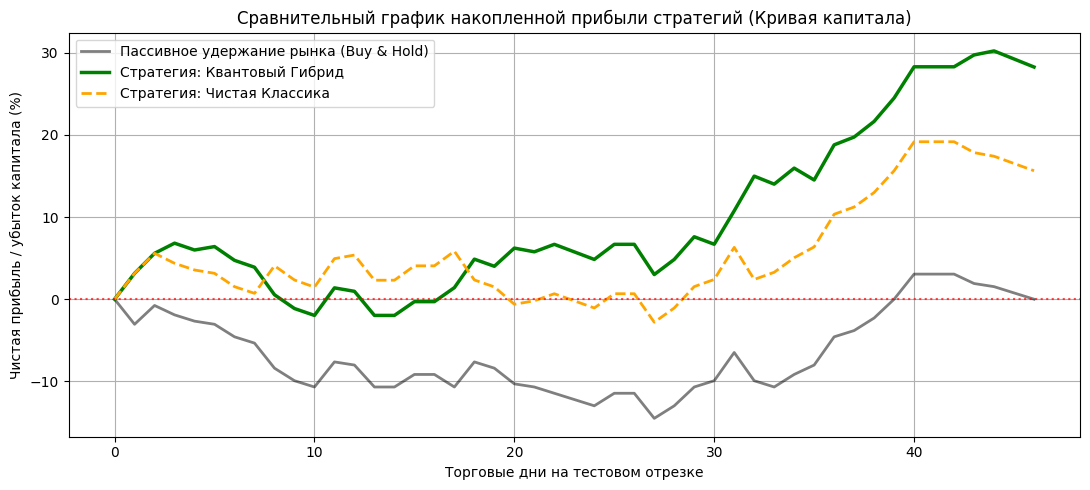

In [307]:
# ====================================================================
# 7. БЛОК СИМУЛЯЦИИ ТОРГОВЛИ И РАСЧЕТА ПРИБЫЛИ (BACKTESTING)
# ====================================================================
def run_trading_backtest(real_actuals, hybrid_preds, classic_preds):
    """
    Симулирует торговлю на тестовом отрезке рынка.
    real_actuals: реальные лог-доходности рынка
    hybrid_preds: прогнозы квантовой модели
    classic_preds: прогнозы классической модели
    """
    # Создаем DataFrame для удобства расчета торговых метрик
    df_trade = pd.DataFrame({
        'market_returns': real_actuals,
        'hybrid_pred': hybrid_preds,
        'classic_pred': classic_preds
    })
    
    # Генерируем торговые сигналы: +1 (Long), -1 (Short)
    # Если прогноз > 0, покупаем. Если < 0, продаем в шорт.
    df_trade['hybrid_signal'] = np.where(df_trade['hybrid_pred'] > 0, 1, -1)
    df_trade['classic_signal'] = np.where(df_trade['classic_pred'] > 0, 1, -1)
    
    # Считаем доходность стратегий на каждый день
    # Мы умножаем сигнал текущего дня на реальную доходность этого дня
    df_trade['hybrid_strategy_returns'] = df_trade['hybrid_signal'] * df_trade['market_returns']
    df_trade['classic_strategy_returns'] = df_trade['classic_signal'] * df_trade['market_returns']
    
    # Переводим лог-доходности в кумулятивную (накопленную) реальную прибыль.
    # Формула: exp(sum(log_returns)) - 1, чтобы получить чистый прирост капитала в процентах.
    df_trade['market_cum'] = (np.exp(df_trade['market_returns'].cumsum()) - 1) * 100.0
    df_trade['hybrid_cum'] = (np.exp(df_trade['hybrid_strategy_returns'].cumsum()) - 1) * 100.0
    df_trade['classic_cum'] = (np.exp(df_trade['classic_strategy_returns'].cumsum()) - 1) * 100.0
    
    # Выводим текстовые финансовые результаты в консоль
    print("\n====================================================")
    print("💰 ФИНАНСОВЫЕ РЕЗУЛЬТАТЫ СИМУЛЯЦИИ ТОРГОВЛИ (В ПЛЮС):")
    print("====================================================")
    print(f"  📈 Пассивная стратегия (Купил и держи маркет): {df_trade['market_cum'].iloc[-1]:.2f}%")
    print(f"  🤖 Торговля по КВАНТОВОМУ ГИБРИДУ:            {df_trade['hybrid_cum'].iloc[-1]:.2f}%")
    print(f"  ⚙️ Торговля по ЧИСТОЙ КЛАССИКЕ:              {df_trade['classic_cum'].iloc[-1]:.2f}%")
    print("====================================================\n")
    
    # Строим итоговый финансовый график кривой капитала (Equity Curve)
    plt.figure(figsize=(11, 5))
    plt.plot(df_trade['market_cum'].values, label="Пассивное удержание рынка (Buy & Hold)", color="black", alpha=0.5, linewidth=2)
    plt.plot(df_trade['hybrid_cum'].values, label="Стратегия: Квантовый Гибрид", color="green", linewidth=2.5)
    plt.plot(df_trade['classic_cum'].values, label="Стратегия: Чистая Классика", color="orange", linestyle="--", linewidth=2)
    
    # Линия нулевой прибыли
    plt.axhline(y=0.0, color='red', linestyle=':', alpha=0.7)
    
    plt.title("Сравнительный график накопленной прибыли стратегий (Кривая капитала)")
    plt.xlabel("Торговые дни на тестовом отрезке")
    plt.ylabel("Чистая прибыль / убыток капитала (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Чтобы запустить этот блок, просто вставь вызов этой функции в самый конец твоего кода 
# (внутрь блока if __name__ == "__main__":), передав туда результаты обучения:
run_trading_backtest(real_actuals, final_hybrid_preds, final_classic_preds)